# BFSPL example (host)

Two finite sources, one point lens. Photometry and astrometry from `bagle.model`, compared to the matching point-source (`BSPL`) model with the same masses, fluxes, and geometry.

**Units (phot+astrom)**
- `sep` in mas; `radiusS_pri` / `radiusS_sec` in arcsec.
- $\rho = r_S \times 10^3 / \theta_E$ with $\theta_E$ in mas.

There is no phot-only BFSPL leaf yet, so all figures use `BFSPL_PhotAstrom_noPar_Param1`.

Milestone (e): host figures. Impact parameter is below $\rho$ so the finite-source peak is visible.

In [1]:
%matplotlib inline
from bagle import model
import numpy as np
import matplotlib.pyplot as plt

<frozen importlib._bootstrap>:491: FutureWarning: pybind11-bound class 'celerite.solver.CholeskySolver' is using an old-style placement-new '__setstate__' which has been deprecated. See the upgrade guide in pybind11's docs. This message is only visible when compiled in debug mode.


## Phot+astrom parameters

| Param | Value | Units |
|---|---|---|
| $m_L$ | 10 | $M_\odot$ |
| $t_0$ | 57000 | MJD |
| $\beta$ | 0.12 | mas |
| $d_L$, $d_S$ | 4000, 8000 | pc |
| $sep$ | 0.4 | mas |
| $\alpha$ | 40 | deg |
| $radiusS_{pri}, radiusS_{sec}$ | $2\times10^{-4}$, $1\times10^{-4}$ | arcsec |
| $b_{sff}$ | 1.0 | |
| $mag_{src,pri}$, $mag_{src,sec}$ | 18.0, 18.6 | |

In [2]:
kw_ps = dict(
    mL=10.0, t0=57000.0, beta=0.12, dL=4000.0, dL_dS=0.5,
    xS0_E=[0.0], xS0_N=[0.0], muL_E=0.0, muL_N=0.0,
    muS_E=3.0, muS_N=0.0, sep=0.4, alpha=40.0,
    mag_src_pri=[18.0], mag_src_sec=[18.6], b_sff=[1.0],
)
bfspl = model.BFSPL_PhotAstrom_noPar_Param1(
    kw_ps['mL'], kw_ps['t0'], kw_ps['beta'], kw_ps['dL'], kw_ps['dL_dS'],
    kw_ps['xS0_E'], kw_ps['xS0_N'], kw_ps['muL_E'], kw_ps['muL_N'],
    kw_ps['alpha'], kw_ps['muS_E'], kw_ps['muS_N'],
    2e-4, 1e-4, kw_ps['sep'], kw_ps['b_sff'],
    kw_ps['mag_src_pri'], kw_ps['mag_src_sec'],
    n_outline_pri=80, n_outline_sec=80,
)
bspl = model.BSPL_PhotAstrom_noPar_Param1(**kw_ps)
t = np.linspace(bfspl.t0 - 1.5 * bfspl.tE, bfspl.t0 + 1.5 * bfspl.tE, 160)
rho_pri = bfspl.radiusS_pri * 1e3 / bfspl.thetaE_amp
rho_sec = bfspl.radiusS_sec * 1e3 / bfspl.thetaE_amp
print(f'thetaE = {bfspl.thetaE_amp:.3f} mas, u0 = {bfspl.u0_amp:.3f}')
print(f'rho_pri = {rho_pri:.3f}, rho_sec = {rho_sec:.3f}, tE = {bfspl.tE:.1f} d')

thetaE = 3.191 mas, u0 = 0.038
rho_pri = 0.063, rho_sec = 0.031, tE = 388.5 d


findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


Text(0.5, 1.0, 'Finite-source residual')

findfont: Failed to find font weight normal, now using 500.


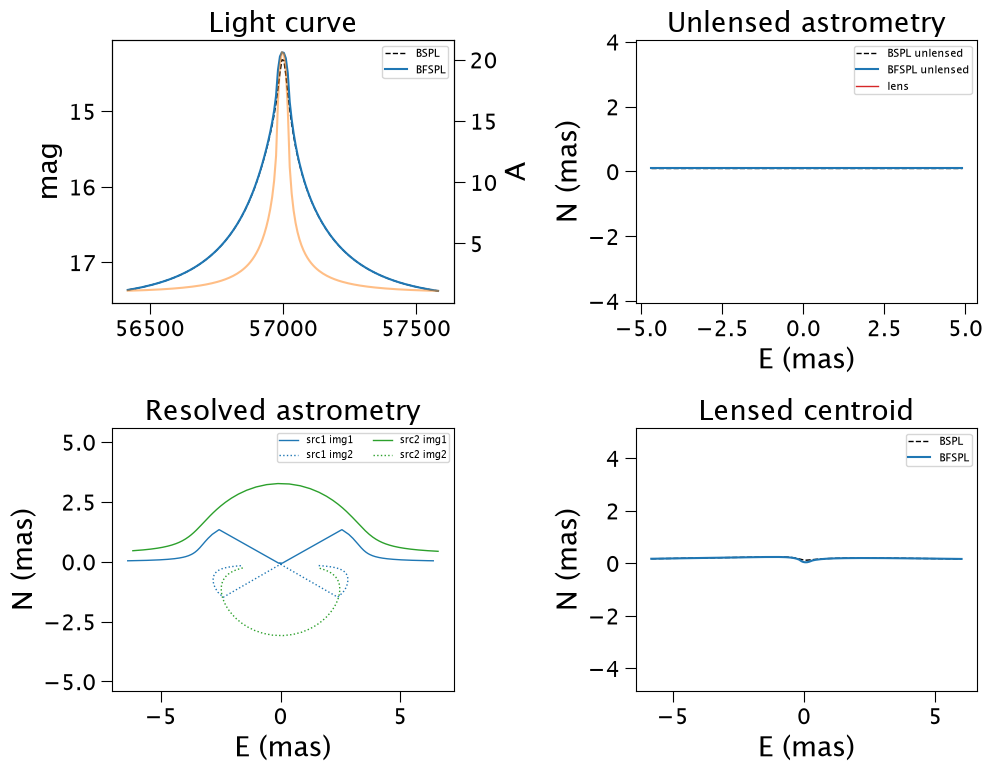

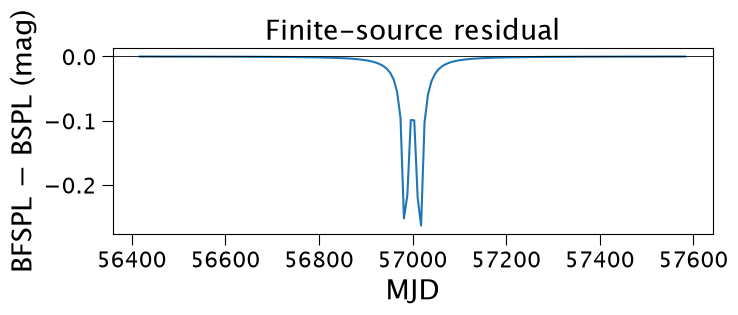

In [3]:
def four_panels(fs, ps, t):
    """Light curve, unlensed sky, resolved images, and lensed centroid."""
    mag_fs = np.asarray(fs.get_photometry(t))
    mag_ps = np.asarray(ps.get_photometry(t))
    amp_fs = np.asarray(fs.get_amplification(t))
    xU_fs = np.asarray(fs.get_astrometry_unlensed(t)) * 1e3
    xU_ps = np.asarray(ps.get_astrometry_unlensed(t)) * 1e3
    xL = np.asarray(fs.get_lens_astrometry(t)) * 1e3
    xR = np.asarray(fs.get_resolved_astrometry(t)) * 1e3
    xA_fs = np.asarray(fs.get_astrometry(t)) * 1e3
    xA_ps = np.asarray(ps.get_astrometry(t)) * 1e3

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    ax = axes[0, 0]
    ax.plot(t, mag_ps, 'k--', lw=1, label='BSPL')
    ax.plot(t, mag_fs, 'C0', lw=1.5, label='BFSPL')
    ax.set_ylabel('mag')
    ax.invert_yaxis()
    ax.legend(loc='best', fontsize=8)
    ax.set_title('Light curve')
    ax2 = ax.twinx()
    ax2.plot(t, amp_fs, 'C1', alpha=0.5)
    ax2.set_ylabel('A')

    ax = axes[0, 1]
    ax.plot(xU_ps[:, 0], xU_ps[:, 1], 'k--', lw=1, label='BSPL unlensed')
    ax.plot(xU_fs[:, 0], xU_fs[:, 1], 'C0', lw=1.5, label='BFSPL unlensed')
    ax.plot(xL[:, 0], xL[:, 1], 'C3', lw=1, label='lens')
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_aspect('equal', adjustable='datalim')
    ax.legend(fontsize=8)
    ax.set_title('Unlensed astrometry')

    ax = axes[1, 0]
    # Resolved: (N, S, I, 2). One color per source, one style per image.
    styles = ('-', ':')
    colors = ('C0', 'C2')
    for s in range(xR.shape[1]):
        for i in range(xR.shape[2]):
            track = xR[:, s, i]
            ok = np.isfinite(track).all(axis=1)
            ax.plot(track[ok, 0], track[ok, 1], color=colors[s],
                    ls=styles[i % 2], lw=1,
                    label=f'src{s + 1} img{i + 1}' if i < 2 else None)
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_aspect('equal', adjustable='datalim')
    ax.legend(fontsize=7, ncol=2)
    ax.set_title('Resolved astrometry')

    ax = axes[1, 1]
    ax.plot(xA_ps[:, 0], xA_ps[:, 1], 'k--', lw=1, label='BSPL')
    ax.plot(xA_fs[:, 0], xA_fs[:, 1], 'C0', lw=1.5, label='BFSPL')
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_aspect('equal', adjustable='datalim')
    ax.legend(fontsize=8)
    ax.set_title('Lensed centroid')

    fig.tight_layout()
    return mag_fs, mag_ps


mag_fs, mag_ps = four_panels(bfspl, bspl, t)
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot(t, mag_fs - mag_ps, 'C0')
ax.axhline(0.0, color='k', lw=0.6)
ax.set_xlabel('MJD')
ax.set_ylabel('BFSPL $-$ BSPL (mag)')
ax.set_title('Finite-source residual')